# ¿Qué aporta replanificar determinísticamente por escenario?

**Pregunta:** ¿Cuánto mejora una resolución determinista económica al mejor plan fijado antes de cada realización geológica?

**Nivel:** 3 · comparación con métodos publicados

**Prerrequisitos:** Complete primero los notebooks 01 y 02 de incertidumbre.

**Tiempo de lectura:** 24 minutos


## Objetivos

Este notebook mide qué puede establecer la replanificación determinista en un caso pequeño de PhaseFlow. Antes de observar una realización, selecciona un único plan fijo con la mayor media de valor en el conjunto compartido. Para cada vector de valores sintético, una búsqueda de vecindarios C-PIT[D] exacta parte de ese mismo plan. Se examinan las ganancias pareadas de VPN, la configuración que conserva la factibilidad y los límites de interpretar la búsqueda local como una cota inferior de EVPI. Es un experimento computacional, no un plan minero estocástico.


## Preparación

Instale el paquete de métodos fijado para este notebook desde la raíz. La celda de imports informa las versiones activas; ninguna celda instala paquetes.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importe la canalizacion y las API de paquetes usadas en este notebook.
import dataclasses
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

La canalización de PhaseFlow, con licencia MIT, construye una veta sintética declarada (bloques 4×4×3, semilla 31, cuatro períodos, descuento de 8 %). El conjunto tiene 24 realizaciones sintéticas equiprobables y correlacionadas espacialmente, generadas por OreBlocks 0.6.6 con sigma 0.25, suavizado de dos bloques y semilla 19. No son simulaciones condicionales ni incorporan condicionamiento de sondajes. Recursos, precedencias, descuento y horizonte se mantienen fijos; solo cambian los valores por bloque. Por eso el experimento aísla cambios de valor y no permite concluir sobre tonelaje, costos, capacidad ni probabilidades geológicas reales.

## Método

Para una asignación temporal tau y un vector de valores v, el valor descontado es V(tau,v)=sum[b:tau_b>=0] v_b(1+rho)^(-tau_b). La política ex ante se selecciona una sola vez, maximizando el VPN medio entre las realizaciones con semilla fija. En cada realización, los MILP restringidos C-PIT[D] exactos buscan desde el mismo plan factible inicial. Una brecha MIP, tamaño de vecindario, número de rondas y secuencia de semillas fijos permiten reproducir el experimento. Los MILP restringidos se resuelven exactamente hasta su brecha; la selección aleatoria de vecindarios sigue siendo heurística. Comparamos el VPN factible resultante con el VPN de esa misma política en la realización. La mejora media es una cota inferior de EVPI, no una solución estocástica globalmente óptima.


### Paso 1: construir el caso declarado

Declare el mismo caso didáctico de 48 bloques de los notebooks 01 y 02, y constrúyalo con la canalización identificada de PhaseFlow. El informe de contrato y el número de bloques permiten detectar cambios de entrada antes de atribuir resultados a la incertidumbre. La definición del escenario, no un plan precalculado, alimenta todos los métodos siguientes.

In [2]:
# Construya el caso sintetico declarado con la canalizacion del producto.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contrato valido:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato valido: True | bloques: 48


### Paso 2: preparar el plan de referencia y el menú fijo

Resuelva una vez el caso pronosticado con el procedimiento de tiempos esperados del paquete. Este es el plan disponible antes de conocer resultados geológicos. Conservarlo junto a dos planes alternativos crea un menú finito y explícito; no representa todos los planes factibles.

In [3]:
# Calcule candidatos fijos antes de observar las realizaciones.
forecast, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='expected',
    local_search=True,
)
gershon_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='gershon',
    local_search=True,
)
greedy_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='greedy',
    local_search=True,
)
print(forecast.method, round(forecast.npv, 2))
print(gershon_fixed.method, round(gershon_fixed.npv, 2))
print(greedy_fixed.method, round(greedy_fixed.npv, 2))

toposort:expected[r1]+shift-ls 179191.57
toposort:gershon+shift-ls -74237.99
toposort:greedy+shift-ls 179593.14


### Paso 3: generar las realizaciones comunes

Genere el conjunto con la API del paquete y su semilla fija. Las mismas realizaciones se reutilizan después, por lo que la comparación es pareada: un método no recibe escenarios más fáciles que otro. Confirme la cantidad de realizaciones y la semilla como parte de la trazabilidad.

In [4]:
# Genere un conjunto reproducible mediante la API del paquete.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('realizaciones:', ensemble.n_realisations, '| semilla:', ensemble.seed)

realizaciones: 24 | semilla: 19


### Paso 4: puntuar el menú fijo antes de replanificar

Evalúe cada candidato fijo en todas las realizaciones. La matriz permite seleccionar una política ex ante por su media y muestra cómo cambia el ganador del menú al observar cada realización. Ese ganador por realización es solo un oráculo diagnóstico; no se usa como base del valor de replanificación.


In [5]:
# Puntue cada candidato fijo en todas las realizaciones compartidas.
fixed_schedules = {
    forecast.method: forecast.period_of_block,
    gershon_fixed.method: gershon_fixed.period_of_block,
    greedy_fixed.method: greedy_fixed.period_of_block,
}
fixed_scores = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
)
print('mejor por media:', fixed_scores.best_by_expected)
print('media del mejor plan fijo:', round(float(fixed_scores.expected.max()), 2))

mejor por media: toposort:expected[r1]+shift-ls
media del mejor plan fijo: 173035.23


### Paso 5: replanificar desde una política fija

Para cada realización, copie el mismo plan fijo ex ante de mayor media al CPIT específico y ejecute la búsqueda de vecindarios C-PIT[D] acotada por nodos de OreBlocks. Los MILP restringidos usan una brecha y una secuencia de semillas fijas; la selección repetida de vecindarios sigue siendo heurística. Por ello, la media factible es una cota inferior de EVPI, no un óptimo estocástico global. Conservamos el VPN inicial y comprobamos que la búsqueda local no lo reduzca. Los solves restringidos usan un límite determinista de 2.000 nodos, conservan cada incumbente factible y solo reportan optimalidad cuando queda demostrada.


## Comparación

Blom, Pearce y Cote describen la resolución de instancias deterministas bajo incertidumbre geológica. Este notebook estudia esa práctica con realizaciones pareadas. El solver C-PIT[D] exacto optimiza cada vecindario restringido desde una política ex ante fija; la selección repetida de vecindarios sigue siendo heurística. No equivale a un programa estocástico globalmente óptimo ni certifica EVPI. El experimento se limita a una veta sintética de 48 bloques y 24 realizaciones equiprobables con semilla declarada.


In [6]:
# Replanifique cada realizacion desde la misma politica fija de mayor media.
replanned = []
replan_values = []
best_fixed_index = int(np.argmax(fixed_scores.expected))
fixed_ex_ante = fixed_scores.matrix[best_fixed_index]
fixed_method = fixed_scores.method_ids[best_fixed_index]
fixed_plan = np.asarray(fixed_schedules[fixed_method], dtype=np.int64)
for k, draw_values in enumerate(ensemble.values):
    draw_cpit = dataclasses.replace(instance.cpit, value=draw_values)
    start_npv = float(fixed_ex_ante[k])
    start = ob.ScheduleResult(
        method=f'fixed:{fixed_method}', period_of_block=fixed_plan.copy(), npv=start_npv,
    )
    schedule = ob.exact_local_search(
        draw_cpit, instance.precedence, start, d_max=48, rounds=16,
        seed=31 + k, time_limit=None, node_limit=2_000, mip_gap=1e-5,
    )
    if schedule.npv < start_npv - 1e-6 * max(1.0, abs(start_npv)):
        raise AssertionError(f'la replanificacion redujo la politica fija en la realizacion {k}')
    replanned.append(schedule)
    replan_values.append(max(start_npv, float(schedule.npv)))
replan_values = np.asarray(replan_values)
print('politica fija:', fixed_method, '| re-resoluciones:', len(replanned),
      '| primer VPN:', round(float(replan_values[0]), 2))


politica fija: toposort:expected[r1]+shift-ls | re-resoluciones: 24 | primer VPN: 203306.27


### Paso 6: calcular la ganancia pareada de replanificación

La base ex ante es el único candidato con mayor media entre todas las realizaciones. Cada replanificación parte de esa misma política y puede mejorarla para el vector de valores observado. Comparamos el VPN replanificado con el VPN de esa misma política en el mismo vector; la ganancia media es no negativa salvo tolerancia numérica. Como la búsqueda local produce planes factibles y no óptimos globales por realización, la ganancia medida es una cota inferior de EVPI para este conjunto sintético.


In [7]:
# Compare cada replanificacion con la misma politica ex ante en realizaciones pareadas.
paired_gain = replan_values - fixed_ex_ante
replan_result = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
    per_realisation_optimum=replan_values,
)
print('valor medio de replanificacion (cota inferior de EVPI):', round(replan_result.value_of_replanning, 2))
print('ganancia pareada media:', round(float(paired_gain.mean()), 2))
print('P10/P90:', round(float(np.quantile(paired_gain, 0.10)), 2),
      round(float(np.quantile(paired_gain, 0.90)), 2))
print('realizaciones con ganancia positiva:', int(np.count_nonzero(paired_gain > 1e-9)), '/', len(paired_gain))


valor medio de replanificacion (cota inferior de EVPI): 60459.19
ganancia pareada media: 60459.19
P10/P90: 52730.97 68739.14
realizaciones con ganancia positiva: 24 / 24


### Comparación de distribuciones

El panel izquierdo compara el pronóstico, la política fija seleccionada por su valor esperado y la política replanificada sobre las mismas realizaciones. El derecho muestra las ganancias pareadas frente a esa única política fija. Así se observan la distribución y la cola, y quedan visibles las realizaciones con ganancia nula. Las 24 realizaciones son un experimento diseñado, no muestras inferenciales de un modelo de yacimiento calibrado.


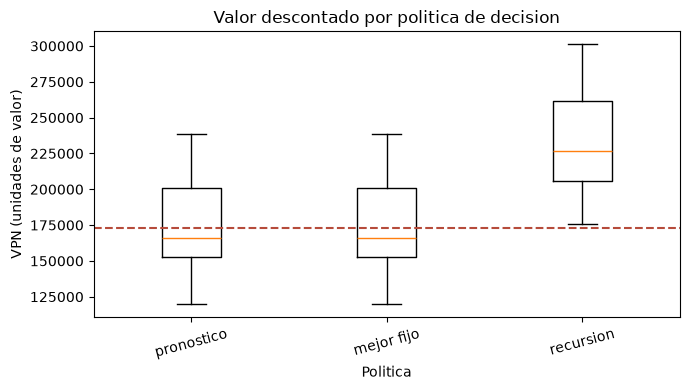

In [8]:
# Compare politicas fijas con el valor de recursividad por escenario.
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([fixed_scores.matrix[0], fixed_ex_ante, replan_values],
    tick_labels=['pronostico', 'mejor fijo', 'recursion'])
ax.axhline(fixed_scores.expected.max(), color='#b64b3b', linestyle='--')
ax.set(title='Valor descontado por politica de decision',
    xlabel='Politica', ylabel='VPN (unidades de valor)')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

Cada caja resume valores descontados en las mismas 24 realizaciones sintéticas. Las políticas de pronostico y mejor fija conservan un único plan en todas; cada replanificación parte del plan mejor fijo y puede mejorarlo para esa realización. La línea discontinua marca la media ex ante del mejor plan fijo, no un óptimo de referencia. Las medianas y la dispersión describen solo este experimento con semilla fija.


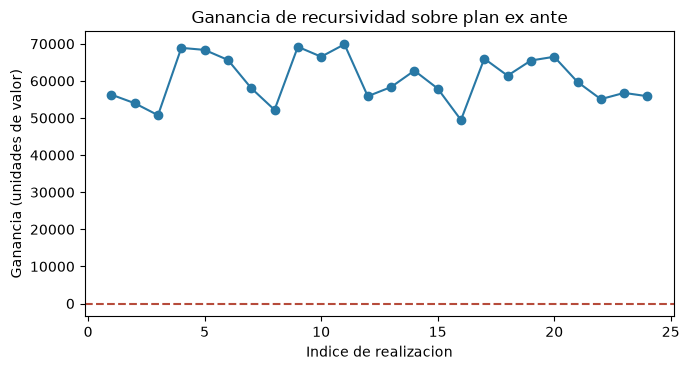

In [9]:
# Grafique la ganancia de recursividad y la referencia cero por realizacion.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, len(paired_gain) + 1), paired_gain,
    marker='o', color='#2878a5')
ax.axhline(0, color='#b64b3b', linestyle='--')
ax.set(title='Ganancia de recursividad sobre plan ex ante',
    xlabel='Indice de realizacion', ylabel='Ganancia (unidades de valor)')
fig.tight_layout()
plt.show()

### Figura 2

Cada punto es el VPN replanificado menos el VPN de la misma política mejor fija en esa realización. Toda replanificación parte de la política fija y la búsqueda restringida conserva su incumbente; las ganancias deben ser no negativas salvo tolerancia numérica. La media es una cota inferior factible de EVPI porque la búsqueda local puede omitir mejores planes. No certifica un óptimo global de recursión.


### Paso 7: comparar la coherencia espacial

Las mismas realizaciones de valor pueden producir planes con distribuciones espaciales distintas. Use `schedule_coherence` de OreBlocks sobre el plan fijo ex ante y sobre cada plan replanificado. El resumen informa el promedio de componentes conexas por período activo, la fracción conjunta de bloques extraídos que pertenece a la componente mayor y el percentil diez del ancho mínimo medido en bloques. Ese ancho es un indicador geométrico, no metros ni una certificación de ancho operacional; el resumen tampoco sustituye las verificaciones de precedencia y capacidad. Como el caso modifica solo los valores, las diferencias provienen del plan elegido al replanificar y no de cambios en la geometría.


In [10]:
# Mida resúmenes espaciales para la política fija y cada plan replanificado.
def geometry_summary(period_assignment):
    period_rows = ob.schedule_coherence(
        period_assignment, instance.x, instance.y, instance.level, n_periods=4,
    )
    active = [row for row in period_rows if row.blocks > 0]
    total_blocks = sum(row.blocks for row in active)
    return {
        'components_per_period': float(np.mean([row.components for row in active])),
        'largest_component_share': sum(row.largest_component for row in active) / total_blocks,
        'minimum_width_blocks': min(row.min_width_blocks for row in active),
    }

fixed_geometry = geometry_summary(fixed_plan)
replanned_geometry = [geometry_summary(row.period_of_block) for row in replanned]
print('fijo componentes/fracción/ancho mínimo:',
      round(fixed_geometry['components_per_period'], 2),
      round(fixed_geometry['largest_component_share'], 3),
      fixed_geometry['minimum_width_blocks'])
print('promedio replanificado de componentes/fracción:',
      round(float(np.mean([row['components_per_period'] for row in replanned_geometry])), 2),
      round(float(np.mean([row['largest_component_share'] for row in replanned_geometry])), 3))
print('P10 del ancho mínimo replanificado:',
      round(float(np.quantile([row['minimum_width_blocks'] for row in replanned_geometry], 0.10)), 2))


fijo componentes/fracción/ancho mínimo: 3.0 0.438 1
promedio replanificado de componentes/fracción: 1.14 0.929
P10 del ancho mínimo replanificado: 1.0


## Resultados

**Respuesta:** La búsqueda local con límite de nodos produjo una ganancia pareada media de **60.459,19 unidades de valor** sobre la política fija ex ante (P10 52.730,97; P90 68.739,14; 24 de 24 realizaciones con mejora). La ganancia es una cota inferior de EVPI para este caso sintético; no es EVPI ni una solución estocástica global.


In [11]:
# Muestre las metricas calculadas citadas en la respuesta.
print(f'ganancia_media={paired_gain.mean():.2f}')
print(f'P10={np.quantile(paired_gain, 0.10):.2f}; P90={np.quantile(paired_gain, 0.90):.2f}')
print(f'escenarios_mejorados={(paired_gain > 1e-9).mean():.3f}')

ganancia_media=60459.19
P10=52730.97; P90=68739.14
escenarios_mejorados=1.000


## Resumen

El experimento selecciona una política antes de observar las realizaciones y luego mide cómo los MILP restringidos exactos C-PIT[D] pueden mejorarla tras cada vector de valores. La ganancia pareada factible es no negativa salvo tolerancia numérica y constituye una cota inferior de EVPI; la búsqueda aleatoria externa no certifica una recursión óptima global. Las conclusiones se limitan a una veta sintética de 48 bloques, 24 realizaciones equiprobables con semilla fija, y tonelaje y capacidad constantes. Un estudio de campo requiere simulaciones condicionales con procedencia, pesos calibrados, incertidumbre en entradas relevantes, controles operacionales y un método con certificado de optimalidad global.


## Referencias

- Blom, Pearce y Cote, análisis determinista por escenarios en minería: https://arxiv.org/abs/2403.18213.
- Ramazan y Dimitrakopoulos, programación entera estocástica de dos etapas: https://doi.org/10.1007/s11081-012-9186-2.
- OreBlocks 0.6.6, `exact_local_search`, `perturb_values` y `evaluate_across`: https://pypi.org/project/oreblocks/.
- Esquema y constructor de PhaseFlow: `data-pipeline/pipeline/io/schema.py` y `data-pipeline/pipeline/model/instances.py` (MIT).
